In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Subset
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from collections import defaultdict
from tqdm import tqdm

import sys
sys.path.append('..')
from utils import ising_data_builder, H5IsingDataset

# recontronstrucción 
Queremos pasar de una tarea de clasificación de fase (una etiqueta por configuración) a una tarea de inpainting / imputación: ocultar deliberadamente un pequeño porcentaje de spins (ej. 5%) y entrenar un modelo para predecir las posiciones ocultas. Con esto medimos cuánto el modelo ha aprendido las correlaciones del sistema y usamos la dificultad de reconstrucción para detectar propiedades físicas 



## Construcción del Dataset y train / test split



In [2]:
# Crear el dataset
data = ising_data_builder('../data/data_20/', kind='inpainting').h5_path
dataset = H5IsingDataset(data)

n = len(dataset)

# Train / Test Split 
train_idx, test_idx = train_test_split(
    np.arange(n),
    test_size=0.2,
    random_state=4
)

# Subsets que no copian datos, solo crean vistas por índices
train_set = Subset(dataset, train_idx.tolist())
test_set = Subset(dataset, test_idx.tolist())

# DataLoaders -> genera los batches
train_loader = DataLoader(train_set, batch_size=64, shuffle=True, num_workers=0)
test_loader = DataLoader(test_set, batch_size=64, shuffle=False, num_workers=0)

In [ ]:
# dataset.close()

## Modelo 

In [3]:
n = 20  # Tamaño del lattice 

# Bloques de la u-net
class DoubleConv(nn.Module):
    """Conv2d → BN → ReLU → Conv2d → BN → ReLU"""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.net(x)

class Down(nn.Module):
    """MaxPool + DoubleConv"""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.MaxPool2d(2),
            DoubleConv(in_ch, out_ch)
        )
    def forward(self, x):
        return self.net(x)

class Up(nn.Module):
    """Upsample + Conv + DoubleConv"""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, out_ch, 2, stride=2)
        self.conv = DoubleConv(in_ch, out_ch)

    def forward(self, x1, x2):
        x1 = self.up(x1)

        # Padding si las dimensiones no coinciden por divisiones impares
        diffY = x2.size()[2] - x1.size()[2]
        diffX = x2.size()[3] - x1.size()[3]
        x1 = nn.functional.pad(
            x1,
            [diffX // 2, diffX - diffX // 2,
             diffY // 2, diffY - diffY // 2]
        )

        x = torch.cat([x2, x1], dim=1)
        return self.conv(x)

class OutConv(nn.Module):
    """Última capa (sin sigmoide porque se usa BCEWithLogitsLoss)"""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Conv2d(in_ch, out_ch, kernel_size=1)

    def forward(self, x):
        return self.conv(x)

# U-NET
class UNetIsing(nn.Module):
    def __init__(self, n_channels=1, out_channels=1):
        super().__init__()

        self.inc = DoubleConv(n_channels, 64)
        self.down1 = Down(64, 128)
        self.down2 = Down(128, 256)
        self.down3 = Down(256, 512)

        self.up1 = Up(512, 256)
        self.up2 = Up(256, 128)
        self.up3 = Up(128, 64)

        self.outc = OutConv(64, out_channels)

    def forward(self, x):
        if x.dim() == 3:  # (batch, n, n)
            x = x.unsqueeze(1)

        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)

        x = self.up1(x4, x3)
        x = self.up2(x,  x2)
        x = self.up3(x,  x1)

        logits = self.outc(x)   # (batch, 1, n, n)
        return logits

# Inicialización del modelo
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = UNetIsing(n_channels=2, out_channels=1).to(device)
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [4]:
# Cargar modelo entrenado

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = UNetIsing(n_channels=2, out_channels=1).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# Cargar hiperparámetros ya entrenados
checkpoint_path = "./experiments/unet_ising/model.pt"
checkpoint = torch.load(checkpoint_path, map_location=device)
model.load_state_dict(checkpoint["model_state"]) # Restaurar pesos
optimizer.load_state_dict(checkpoint["optimizer_state"])


## Entrenamiento y evaluación


In [5]:
import torch
import torch.nn.functional as F

# Parámetros 
pct_mask = 0.05   # 5% enmascarado
eps = 1e-8        # para evitar división por cero

# Usamos BCE por elemento, sin reducción, para poder enmascarar
loss_fn_elem = nn.BCEWithLogitsLoss(reduction='none')

def train_epoch(model, loader, pct_mask=pct_mask):
    model.train()
    total_masked_loss = 0.0
    total_masked_pixels = 0.0
    total_masked_correct = 0.0  # para masked accuracy
    total_examples = 0

    for batch_idx, (X, y) in enumerate(loader):
        # X: (B, 1, n, n) o (B, n, n)  con valores 0/1
        # y: (B, 1, n, n) o (B, n, n)  targets en 0/1
        if X.dim() == 3:
            X = X.unsqueeze(1)
        if y.dim() == 3:
            y = y.unsqueeze(1)

        X = X.to(device).float()
        y = y.to(device).float()

        B, _, H, W = X.shape
        device_local = X.device

        # 1) generar máscara aleatoria por batch: mask_obs = 1 observed, 0 masked
        #    usamos thresholding: aproximadamente pct_mask fracción en 0
        mask_obs = (torch.rand((B, 1, H, W), device=device_local) > pct_mask).float()

        # 2) preparar input: canal estado con huecos a 0, y canal máscara
        state_masked = X * mask_obs
        model_input = torch.cat([state_masked, mask_obs], dim=1)  # (B,2,H,W)

        # 3) forward + loss por elemento (no reducido)
        logits = model(model_input)            # (B,1,H,W)
        loss_mat = loss_fn_elem(logits, y)     # (B,1,H,W)

        # 4) aplicar máscara de evaluación: mask_eval = 1 donde estaba oculto
        mask_eval = (1.0 - mask_obs)           # 1 para posiciones que queremos evaluar

        # 5) loss agregado solo sobre píxeles enmascarados
        masked_loss_sum = (loss_mat * mask_eval).sum()
        n_masked = mask_eval.sum().item()
        loss = masked_loss_sum / (n_masked + eps)

        # 6) backward + step
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # 7) acumular métricas
        total_masked_loss += masked_loss_sum.item()
        total_masked_pixels += n_masked

        with torch.no_grad():
            probs = torch.sigmoid(logits)
            preds = (probs >= 0.5).float()
            correct_masked = (((preds == y) * mask_eval).sum().item())
            total_masked_correct += correct_masked

        total_examples += B

    # medias finales
    masked_loss_mean = total_masked_loss / (total_masked_pixels + eps)
    masked_acc = total_masked_correct / (total_masked_pixels + eps)

    return masked_loss_mean, masked_acc

def eval_epoch(model, loader, pct_mask=pct_mask):
    model.eval()
    total_masked_loss = 0.0
    total_masked_pixels = 0.0
    total_masked_correct = 0.0
    total_examples = 0

    with torch.no_grad():
        for batch_idx, (X, y) in enumerate(loader):
            if X.dim() == 3:
                X = X.unsqueeze(1)
            if y.dim() == 3:
                y = y.unsqueeze(1)

            X = X.to(device).float()
            y = y.to(device).float()

            B, _, H, W = X.shape
            device_local = X.device

            # máscara aleatoria para evaluación (si prefieres reproducible, pre-genera y cárgala)
            mask_obs = (torch.rand((B, 1, H, W), device=device_local) > pct_mask).float()

            state_masked = X * mask_obs
            model_input = torch.cat([state_masked, mask_obs], dim=1)

            logits = model(model_input)
            loss_mat = loss_fn_elem(logits, y)

            mask_eval = (1.0 - mask_obs)

            masked_loss_sum = (loss_mat * mask_eval).sum()
            n_masked = mask_eval.sum().item()

            total_masked_loss += masked_loss_sum.item()
            total_masked_pixels += n_masked

            probs = torch.sigmoid(logits)
            preds = (probs >= 0.5).float()
            correct_masked = (((preds == y) * mask_eval).sum().item())
            total_masked_correct += correct_masked

            total_examples += B

    masked_loss_mean = total_masked_loss / (total_masked_pixels + eps)
    masked_acc = total_masked_correct / (total_masked_pixels + eps)

    return masked_loss_mean, masked_acc



In [ ]:
# Loop de entrenamiento
train_losses, train_accs = [], []
test_losses, test_accs = [], []

for epoch in tqdm(range(1, 10), desc="Epochs"):

    # ENTRENAR UNA ÉPOCA CON MÁSCARAS ALEATORIAS
    train_loss, train_acc = train_epoch(model, train_loader)

    # EVALUAR UNA ÉPOCA CON MÁSCARAS ALEATORIAS
    test_loss, test_acc = eval_epoch(model, test_loader)
    
    # Guardar métricas
    train_losses.append(train_loss)
    train_accs.append(train_acc)
    test_losses.append(test_loss)
    test_accs.append(test_acc)


Epochs:   0%|          | 0/9 [00:00<?, ?it/s]

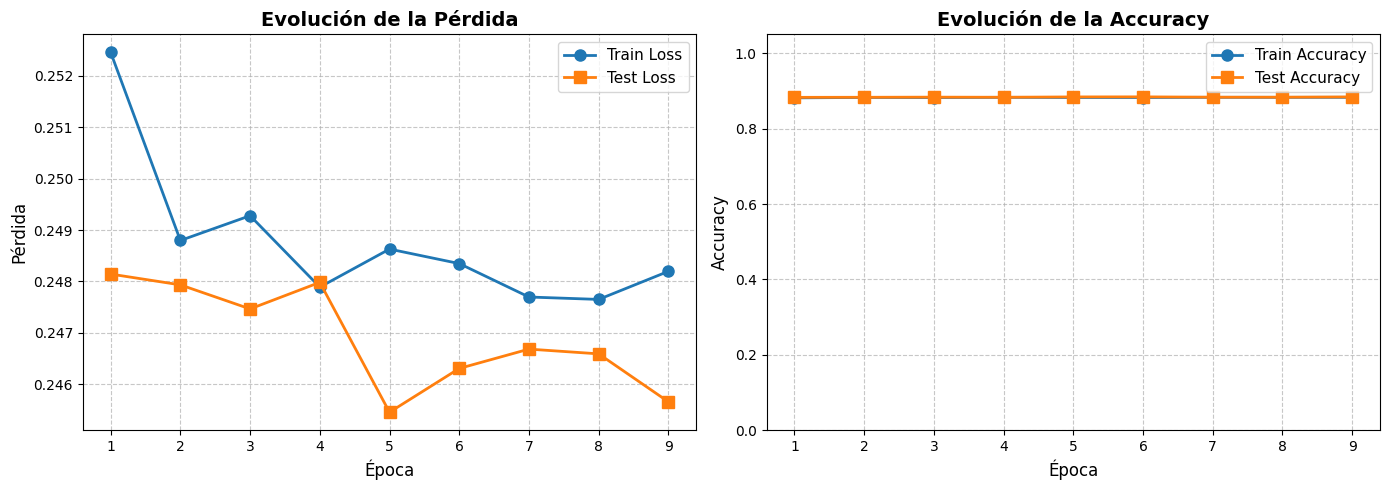

In [ ]:
# Graficar métricas de entrenamiento en un solo plot
epochs = range(1, len(train_losses) + 1)

fig, ax = plt.subplots(figsize=(7, 5))

# Gráfico de pérdida
ax.plot(epochs, train_losses, 'o-', label='Train Loss', linewidth=2, markersize=8)
ax.plot(epochs, test_losses, 's-', label='Test Loss', linewidth=2, markersize=8)
ax.set_xlabel('Época', fontsize=12)
ax.set_ylabel('Pérdida', fontsize=12)
ax.set_title('Evolución de la Pérdida', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, linestyle='--', alpha=0.7)



plt.tight_layout()
plt.savefig('../img_results/training_curves_nn.png', dpi=300, bbox_inches='tight')
plt.show()

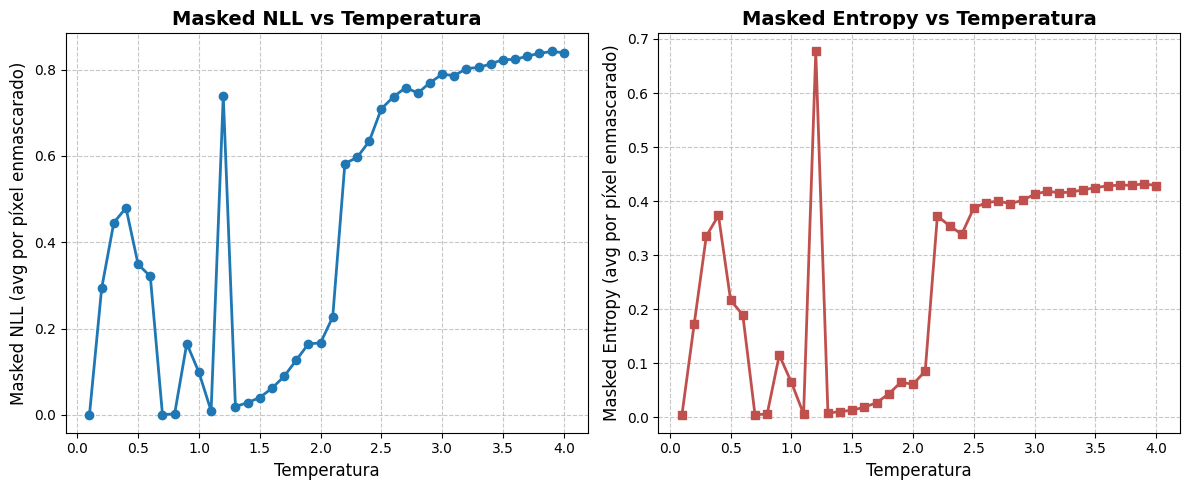

In [36]:
# Evaluación inpainting por temperatura (lee archivos directamente; aplica máscara igual que en train)
import os
import numpy as np
import torch
import torch.nn.functional as F
from collections import defaultdict
import matplotlib.pyplot as plt
from utils import read_ising_file

model.eval()
folder = './../data/data_20/'   # ajusta si hace falta

# Parámetros de máscara (mismo esquema que en train_epoch)
pct_mask = 0.05
seed = 42
eps = 1e-8

# Contenedores por temperatura
metrics_per_temp = defaultdict(lambda: {'nll': [], 'entropy': []})

sample_global_idx = 0  # contador global de muestras para semilla reproducible

for file in os.listdir(folder):
    if 'ising_' not in file:
        continue

    path = os.path.join(folder, file)
    try:
        ising = read_ising_file(path)
        temp = ising.metadata.get('T', None)
        spins = ising.load_all_spins(invert=False)  # lista o array de (H,W) o (N,H,W)

        # asegurar numpy array
        spins = np.array(spins, dtype=np.float32)

        # normalizar a batch
        if spins.ndim == 2:
            spins = spins[np.newaxis, ...]

        B = spins.shape[0]
        H, W = spins.shape[1], spins.shape[2]
        n_total = H * W

        # convertir a tensores en device
        x = torch.tensor(spins, dtype=torch.float32, device=next(model.parameters()).device)  # -1/+1
        y = (x + 1.0) / 2.0   # target prob 0/1
        x = x.unsqueeze(1)    # (B,1,H,W)
        y = y.unsqueeze(1)    # (B,1,H,W)

        with torch.no_grad():
            # Para cada muestra generamos máscara aleatoria igual que en train
            mask_obs = torch.empty((B,1,H,W), device=x.device)
            for i in range(B):
                # reproducible por muestra: seed + sample_global_idx + i
                g = torch.Generator(device='cpu')
                g.manual_seed(seed + sample_global_idx + i)
                # sample uniform and threshold
                rand = torch.rand((H, W), generator=g)
                mask_obs[i,0] = (rand > pct_mask).float()

            # preparar input: channel0 = state masked, channel1 = mask
            state_masked = y * mask_obs
            model_input = torch.cat([state_masked, mask_obs], dim=1)  # (B,2,H,W)

            # forward
            logits = model(model_input)          # (B,1,H,W)
            probs = torch.sigmoid(logits).clamp(eps, 1-eps)

            # masked elementwise BCE (nll) y entropy
            loss_mat = F.binary_cross_entropy_with_logits(logits, y, reduction='none')  # (B,1,H,W)
            mask_eval = (1.0 - mask_obs)  # evaluar donde está enmascarado

            # sumar por muestra y normalizar por número de píxeles enmascarados
            loss_sum = (loss_mat * mask_eval).view(B, -1).sum(dim=1).cpu().numpy()
            p = probs
            entropy_sum = (-(p*torch.log(p) + (1-p)*torch.log(1-p)) * mask_eval).view(B, -1).sum(dim=1).cpu().numpy()
            n_masked_vec = mask_eval.view(B, -1).sum(dim=1).cpu().numpy()

            # acumular métricas normalizadas por píxel enmascarado por temperatura
            for j in range(B):
                nm = float(n_masked_vec[j]) if n_masked_vec[j] > 0 else 1.0
                metrics_per_temp[temp]['nll'].append(loss_sum[j] / nm)
                metrics_per_temp[temp]['entropy'].append(entropy_sum[j] / nm)

        sample_global_idx += B

    except Exception as e:
        # ignora archivos malos pero imprime por si quieres debug
        print(f"Skipping {file}: {e}")
        continue

# Agregar por temperatura (media)
temps_sorted = sorted(metrics_per_temp.keys())
if len(temps_sorted) == 0:
    raise RuntimeError("No temperature buckets found. Revisa carpeta y read_ising_file.")

temps = np.array(temps_sorted)
mean_nll = np.array([np.mean(metrics_per_temp[T]['nll']) for T in temps_sorted])
mean_entropy = np.array([np.mean(metrics_per_temp[T]['entropy']) for T in temps_sorted])

# Graficar (manteniendo la estructura simple que usabas)
plt.figure(figsize=(12,5))

# Masked NLL vs T
plt.subplot(1,2,1)
plt.plot(temps, mean_nll, marker='o', linestyle='-', linewidth=2)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xlabel('Temperatura', fontsize=12)
plt.ylabel('Masked NLL (avg por píxel enmascarado)', fontsize=12)
plt.title('Masked NLL vs Temperatura', fontsize=14, fontweight='bold')

# Masked Entropy vs T
plt.subplot(1,2,2)
plt.plot(temps, mean_entropy, marker='s', linestyle='-', linewidth=2, color='#C0504D')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xlabel('Temperatura', fontsize=12)
plt.ylabel('Masked Entropy (avg por píxel enmascarado)', fontsize=12)
plt.title('Masked Entropy vs Temperatura', fontsize=14, fontweight='bold')

plt.tight_layout()
os.makedirs('../img_results', exist_ok=True)
plt.savefig('../img_results/inpainting_metrics_vs_temperature.png', dpi=300, bbox_inches='tight')
plt.show()


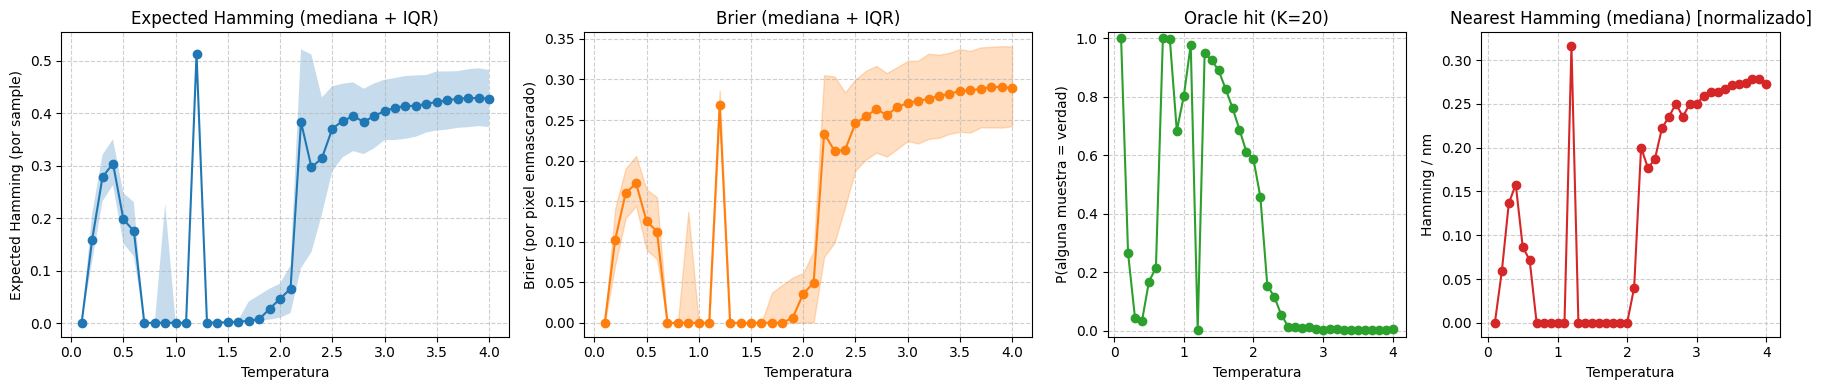

PicklingError: Can't pickle <function <lambda> at 0x0000026AAC02F600>: attribute lookup <lambda> on __main__ failed

In [ ]:
# Evaluación inpainting por temperatura con métricas de multimodalidad
import os
import numpy as np
import torch
import torch.nn.functional as F
from collections import defaultdict
import matplotlib.pyplot as plt
from utils import read_ising_file

device = next(model.parameters()).device
model.eval()
folder = './../data/data_20/'

# Parámetros
pct_mask = 0.05
seed = 42
eps = 1e-8
K = 20  # número de muestras por ejemplo para métricas basadas en sampling

# Contenedores por temperatura (listas de valores por muestra)
metrics_per_temp = defaultdict(lambda: {
    'nll': [], 'entropy': [], 'brier': [], 'exp_hamming': [],
    'oracle_hit': [], 'min_hamming': [], 'mag_error': []
})

sample_global_idx = 0

for file in os.listdir(folder):
    if 'ising_' not in file: 
        continue
    path = os.path.join(folder, file)
    try:
        ising = read_ising_file(path)
        temp = ising.metadata.get('T', None)
        spins = ising.load_all_spins(invert=False)  # lista o array (H,W) o (N,H,W)

        # asegurar numpy array y batch dim
        spins = np.array(spins, dtype=np.float32)
        if spins.ndim == 2:
            spins = spins[np.newaxis, ...]

        B = spins.shape[0]
        H, W = spins.shape[1], spins.shape[2]
        n_total = H * W

        # tensores en device
        x = torch.tensor(spins, dtype=torch.float32, device=device)   # -1/+1
        y = ((x + 1.0) / 2.0).unsqueeze(1)   # (B,1,H,W) target 0/1
        x = x.unsqueeze(1)                  # (B,1,H,W) input

        # generar máscaras reproducibles por muestra (igual que en train)
        mask_obs = torch.empty((B,1,H,W), device=device)
        for i in range(B):
            g = torch.Generator(device='cpu')
            g.manual_seed(seed + sample_global_idx + i)
            rand = torch.rand((H, W), generator=g)
            mask_obs[i,0] = (rand > pct_mask).float()
        mask_eval = (1.0 - mask_obs)   # 1 donde está oculto

        # preparar entrada para la U-Net
        if x.min() < 0:
            state_prob = (x + 1.0) / 2.0
        else:
            state_prob = x.clone()
        state_masked = state_prob * mask_obs
        model_input = torch.cat([state_masked, mask_obs], dim=1)  # (B,2,H,W)

        with torch.no_grad():
            logits = model(model_input)              # (B,1,H,W)
            probs = torch.sigmoid(logits).clamp(eps, 1-eps)

            # elementwise metrics
            loss_mat = F.binary_cross_entropy_with_logits(logits, y, reduction='none')  # (B,1,H,W)
            loss_sum = (loss_mat * mask_eval).view(B, -1).sum(dim=1).cpu().numpy()
            brier_sum = (((probs - y)**2) * mask_eval).view(B, -1).sum(dim=1).cpu().numpy()
            entropy_sum = (-(probs*torch.log(probs) + (1-probs)*torch.log(1-probs)) * mask_eval).view(B, -1).sum(dim=1).cpu().numpy()
            exp_hamming = ((probs * (1.0 - y) + (1.0 - probs) * y) * mask_eval).view(B, -1).sum(dim=1).cpu().numpy()
            n_masked_vec = mask_eval.view(B, -1).sum(dim=1).cpu().numpy() + 1e-12  # evitar /0

            # MÉTRICAS BASADAS EN SAMPLES (K muestras por ejemplo)
            # probs: (B,1,H,W) -> queremos samples shape (K,B,1,H,W)
            probs_rep = probs.unsqueeze(0).repeat(K, 1, 1, 1, 1)  # (K,B,1,H,W)
            samples = torch.bernoulli(probs_rep).cpu().numpy().astype(np.int8)  # 0/1

            # true labels en CPU
            y_cpu = y.cpu().numpy().astype(np.int8)  # (B,1,H,W)
            mask_eval_cpu = mask_eval.cpu().numpy().astype(np.int8)  # (B,1,H,W)

            # calcular oracle_hit y min_hamming por muestra
            # vectorizado: para cada sample j, consideramos masked positions
            for j in range(B):
                nm = float(n_masked_vec[j])
                # extraer muestras K x 1 x H x W  -> shape (K, H*W) only masked positions
                sam_j = samples[:, j, 0].reshape(K, -1)           # (K, H*W)
                true_j = y_cpu[j, 0].reshape(-1)                 # (H*W,)
                mask_j = mask_eval_cpu[j, 0].reshape(-1).astype(bool)  # True where masked

                if mask_j.sum() == 0:
                    # no posiciones enmascaradas (raro), guardamos ceros
                    oracle = 0.0
                    min_h = 0.0
                else:
                    # restrict to masked positions
                    sam_masked = sam_j[:, mask_j]   # (K, nm)
                    true_masked = true_j[mask_j]    # (nm,)

                    # Exact match check across K
                    eq_per_k = np.all(sam_masked == true_masked[None, :], axis=1)  # (K,)
                    oracle = float(np.any(eq_per_k))  # 1.0 if any sample matches exactly

                    # Hamming distances per k
                    ham_k = np.abs(sam_masked - true_masked[None, :]).sum(axis=1)  # (K,)
                    min_h = float(ham_k.min()) / nm  # normalized by nm

                # magnetization error: compare true magnetization to expected magnetization from probs
                # magnetization true using original spins (we can recover from y: s_true = 2*y-1)
                s_true = (2*y_cpu[j,0].astype(np.float32) - 1.0).reshape(-1)  # (H*W,)
                m_true = s_true[mask_j].mean() if mask_j.sum()>0 else np.nan
                # expected spin from probs (E[s]=2p-1)
                p_map = probs[j,0].cpu().numpy().reshape(-1)
                m_pred = (2*p_map[mask_j] - 1.0).mean() if mask_j.sum()>0 else np.nan
                mag_err = float(np.abs(m_pred - m_true)) if mask_j.sum()>0 else 0.0

                # acumular por temperatura (normalizamos las sumas por nm para nll/brier/entropy/exp_hamming)
                metrics_per_temp[temp]['nll'].append(float(loss_sum[j] / nm))
                metrics_per_temp[temp]['brier'].append(float(brier_sum[j] / nm))
                metrics_per_temp[temp]['entropy'].append(float(entropy_sum[j] / nm))
                metrics_per_temp[temp]['exp_hamming'].append(float(exp_hamming[j] / nm))
                metrics_per_temp[temp]['oracle_hit'].append(oracle)
                metrics_per_temp[temp]['min_hamming'].append(min_h)
                metrics_per_temp[temp]['mag_error'].append(mag_err)

        sample_global_idx += B

    except Exception as e:
        print(f"Skipping {file}: {e}")
        continue

# --- Agregar por temperatura (mediana/IQR o media) y plotear ---
temps_sorted = sorted(metrics_per_temp.keys())
if len(temps_sorted) == 0:
    raise RuntimeError("No temperature buckets found. Revisa carpeta y read_ising_file.")

# construir arrays filtrando temperaturas con pocos samples si quieres
min_N = 6
temps = []
med_oracle = []; med_brier=[]; med_eh=[]; q1_b=[]; q3_b=[]; q1_eh=[]; q3_eh=[]; med_min_h=[]; med_mag_err=[]; counts=[]
for T in temps_sorted:
    N = len(metrics_per_temp[T]['nll'])
    if N < min_N:
        continue
    temps.append(T)
    counts.append(N)
    # mediana + IQR para robustez
    med_eh.append(np.median(metrics_per_temp[T]['exp_hamming']))
    q1_eh.append(np.percentile(metrics_per_temp[T]['exp_hamming'], 25))
    q3_eh.append(np.percentile(metrics_per_temp[T]['exp_hamming'], 75))

    med_brier.append(np.median(metrics_per_temp[T]['brier']))
    q1_b.append(np.percentile(metrics_per_temp[T]['brier'],25))
    q3_b.append(np.percentile(metrics_per_temp[T]['brier'],75))

    med_oracle.append(np.mean(metrics_per_temp[T]['oracle_hit']))  # oracle: report mean (probability)
    med_min_h.append(np.median(metrics_per_temp[T]['min_hamming']))
    med_mag_err.append(np.median(metrics_per_temp[T]['mag_error']))

temps = np.array(temps)

# Plot: Expected Hamming (mediana+IQR), Brier (mediana+IQR), Oracle (media)
fig, axes = plt.subplots(1,4, figsize=(18,4), gridspec_kw={'width_ratios':[3,3,2,2]})

# Expected Hamming
axes[0].plot(temps, med_eh, '-o')
axes[0].fill_between(temps, q1_eh, q3_eh, alpha=0.25)
axes[0].set_title('Expected Hamming (mediana + IQR)')
axes[0].set_xlabel('Temperatura'); axes[0].set_ylabel('Expected Hamming (por sample)')
axes[0].grid(True, linestyle='--', alpha=0.6)

# Brier
axes[1].plot(temps, med_brier, '-o', color='C1')
axes[1].fill_between(temps, q1_b, q3_b, color='C1', alpha=0.25)
axes[1].set_title('Brier (mediana + IQR)')
axes[1].set_xlabel('Temperatura'); axes[1].set_ylabel('Brier (por pixel enmascarado)')
axes[1].grid(True, linestyle='--', alpha=0.6)

# Oracle hit (media)
axes[2].plot(temps, med_oracle, '-o', color='C2')
axes[2].set_title(f'Oracle hit (K={K})')
axes[2].set_xlabel('Temperatura'); axes[2].set_ylabel('P(alguna muestra = verdad)')
axes[2].grid(True, linestyle='--', alpha=0.6)
axes[2].set_ylim(-0.02,1.02)

# Min Hamming (mediana)
axes[3].plot(temps, med_min_h, '-o', color='C3')
axes[3].set_title('Nearest Hamming (mediana) [normalizado]')
axes[3].set_xlabel('Temperatura'); axes[3].set_ylabel('Hamming / nm')
axes[3].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
os.makedirs('../img_results', exist_ok=True)
plt.savefig('../img_results/inpainting_multimodal_metrics_vs_T.png', dpi=300, bbox_inches='tight')
plt.show()




1. Expected Hamming Distance
**¿Qué mide?**  
La distancia de Hamming esperada entre la configuración verdadera y la distribución de probabilidad predicha por el modelo.

**Interpretación:**  
Para cada píxel, el error esperado se calcula como:  

$$p(1-y) + (1-p)y$$

donde $p$ es la probabilidad predicha de spin-up y $y$ es el valor real (0/1).  
Promedia el error sin exigir decisiones binarias, por lo que es adecuada cuando múltiples configuraciones son compatibles.

---

2. Brier Score 🟠
**¿Qué mide?**  
El error cuadrático entre la probabilidad predicha por el modelo y el valor observado del spin.

$$ (p-y)^2 $$

**Interpretación:**  
Evalúa qué tan cercanas están las probabilidades del modelo al valor observado, penalizando fuertemente predicciones muy confiadas pero incorrectas.  
Es una métrica estándar de calidad probabilística.

---

3. Oracle Hit (K muestras) 🟢
**¿Qué mide?**  
La probabilidad de que al menos una de las $K$ configuraciones muestreadas desde el modelo coincida exactamente con la configuración verdadera.

**Interpretación:**  
Simula un "oráculo" que sabe elegir la configuración correcta entre varias muestras generadas por el modelo.  
Mide la capacidad del modelo para cubrir el conjunto de posibles soluciones (recall generativo).

---

4. Nearest-Sample Hamming Distance 🔴
**¿Qué mide?**  
La distancia de Hamming entre la configuración verdadera y la mejor (más cercana) de las $K$ muestras generadas por el modelo.
 
**Interpretación:**  
Cuantifica qué tan cerca está el modelo de generar una configuración válida, permitiendo que elija la mejor entre sus muestras.  
Evalúa la calidad del soporte de la distribución generada (qué tan buenas son las muestras).

## Guardar modelo 


In [38]:
import os
import torch

# Crear carpeta
save_dir = "./experiments/unet_ising"
os.makedirs(save_dir, exist_ok=True)

# Path del archivo
model_path = os.path.join(save_dir, "model.pt")

# Guardar el checkpoint
torch.save({
    "model_state": model.state_dict(),
    "optimizer_state": optimizer.state_dict(),
    "hyperparams": {
        "n_channels": 2,
        "out_channels": 1,
        "lr": 1e-3,
        "loss_fn": "BCEWithLogitsLoss",
        "architecture": "UNetIsing",
    }
}, model_path)

# Metadata
import yaml

# Configuración del modelo
config = {
    "model": {
        "architecture": "UNetIsing",
        "n_channels": 2,
        "out_channels": 1,
        "encoder_channels": [64, 128, 256, 512],
        "decoder_channels": [256, 128, 64]
    },
    "training": {
        "optimizer": "Adam",
        "lr": 1e-3,
        "loss": "BCEWithLogitsLoss"
    },
    "experiment": {
        "name": "unet_ising",
        "save_dir": "./experiments/unet_ising"
    }
}

# Guardar YAML
yaml_path = os.path.join(save_dir, "config.yaml")
with open(yaml_path, "w") as f:
    yaml.dump(config, f, sort_keys=False)

print(f"config.yaml guardado en: {yaml_path}")


config.yaml guardado en: ./experiments/unet_ising\config.yaml
